# 01 · Exploratory Data Analysis: PaySim

**Goal:** understand the structure of the PaySim transactions before modelling. The
focus is on what matters for fraud detection: how rare fraud is, where it occurs,
how it moves over time, and which columns are safe to use.

All logic lives in `src/` (`src/data.py`, `src/eda.py`). This notebook only calls
those functions and plots the results. Figures are saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

# Make the project root importable regardless of where Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.data import load_data
from src import eda
from src.plotting import set_style, save_fig, LEGIT_COLOR, FRAUD_COLOR, CLASS_COLORS

np.random.seed(42)
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
df = load_data()  # data/paysim.csv, compact dtypes + schema validation
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6396",C1231006815,"170,136.0000","160,296.3594",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7207",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1396",C2048537720,"41,554.0000","29,885.8594",M1230701703,0.0000,0.0000,0,0


## 1. Shape, dtypes, memory, missing values and duplicates

In [3]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"Fully duplicated rows: {eda.count_duplicates(df):,}")
print(f"Steps covered: {df['step'].min()} to {df['step'].max()} (1 step = 1 hour, ~31 days)")
eda.overview(df)

Shape: 6,362,620 rows x 11 columns
Memory: 394 MB


Fully duplicated rows: 0
Steps covered: 1 to 743 (1 step = 1 hour, ~31 days)


,dtype,n_missing,memory_mb
step,int16,0,12.7000
type,category,0,6.4000
amount,float32,0,25.5000
nameOrig,string,0,117.6000
oldbalanceOrg,float32,0,25.5000
newbalanceOrig,float32,0,25.5000
nameDest,string,0,117.6000
oldbalanceDest,float32,0,25.5000
newbalanceDest,float32,0,25.5000
isFraud,int8,0,6.4000


**Takeaway:** 6,362,620 transactions and 11 columns, with no missing values and no
duplicated rows. The compact dtypes (int16 `step`, float32 money columns, categorical
`type`, int8 labels) keep the full dataset small enough to analyse in memory. The
743 hourly steps cover about 31 simulated days, which is the time axis used for the
train/test split later.

## 2. Class balance

,count,pct
class,,
legit,6354407,99.8709
fraud,8213,0.1291


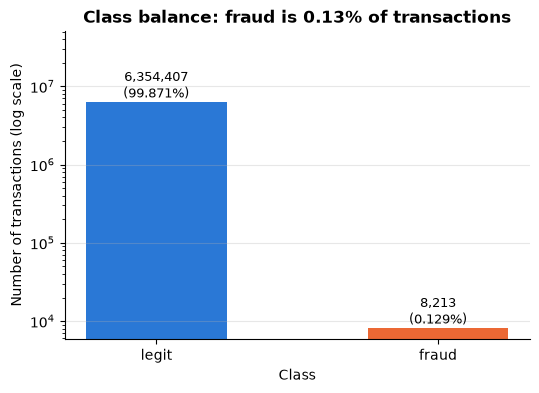

In [4]:
balance = eda.class_balance(df)
display(balance)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(balance.index, balance["count"],
              color=[CLASS_COLORS[c] for c in balance.index], width=0.5)
ax.set_yscale("log")
ax.set_title(f"Class balance: fraud is {balance.loc['fraud', 'pct']:.2f}% of transactions")
ax.set_xlabel("Class")
ax.set_ylabel("Number of transactions (log scale)")
for bar, (cnt, pct) in zip(bars, balance[["count", "pct"]].values):
    ax.annotate(f"{cnt:,.0f}\n({pct:.3f}%)", (bar.get_x() + bar.get_width() / 2, cnt),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(top=balance["count"].max() * 8)
save_fig(fig, "01_class_balance")
plt.show()

**Takeaway:** only **8,213 of 6,362,620 transactions (0.129%) are fraud**, about 1
in 775. A model that always predicts "legit" would be 99.87% accurate and catch no
fraud at all. This is why the project reports PR-AUC, precision and recall, and
never accuracy.

## 3. Fraud by transaction type

,n_txn,n_fraud,fraud_rate_pct
type,,,
CASH_OUT,2237500,4116,0.1840
PAYMENT,2151495,0,0.0000
CASH_IN,1399284,0,0.0000
TRANSFER,532909,4097,0.7688
DEBIT,41432,0,0.0000


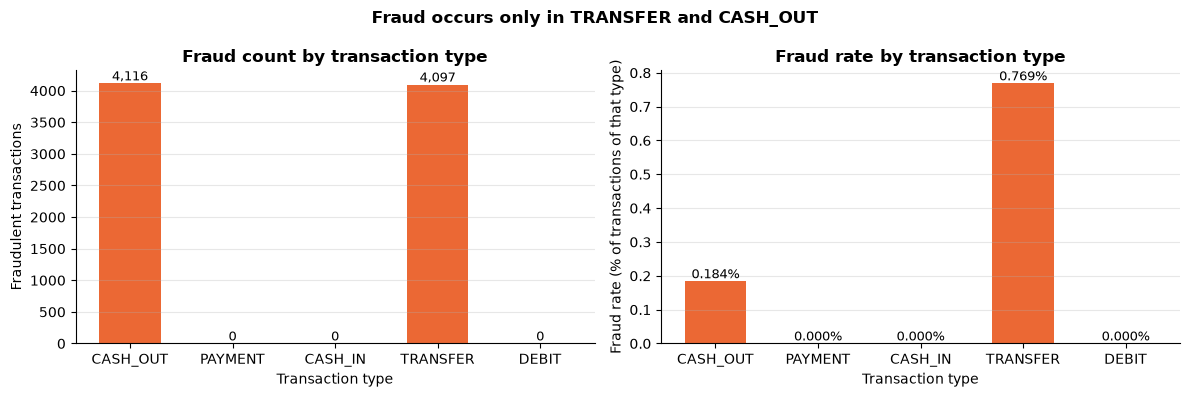

Types containing fraud: ['CASH_OUT', 'TRANSFER']


In [5]:
by_type = eda.fraud_by_type(df)
display(by_type)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = by_type.index.astype(str)
axes[0].bar(order, by_type["n_fraud"], color=FRAUD_COLOR, width=0.6)
axes[0].set_title("Fraud count by transaction type")
axes[0].set_xlabel("Transaction type")
axes[0].set_ylabel("Fraudulent transactions")
axes[1].bar(order, by_type["fraud_rate_pct"], color=FRAUD_COLOR, width=0.6)
axes[1].set_title("Fraud rate by transaction type")
axes[1].set_xlabel("Transaction type")
axes[1].set_ylabel("Fraud rate (% of transactions of that type)")
for ax, col, fmt in [(axes[0], "n_fraud", "{:,.0f}"), (axes[1], "fraud_rate_pct", "{:.3f}%")]:
    for x, v in zip(order, by_type[col]):
        ax.annotate(fmt.format(v), (x, v), ha="center", va="bottom", fontsize=9)
fig.suptitle("Fraud occurs only in TRANSFER and CASH_OUT", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_fraud_by_type")
plt.show()

fraud_types = set(by_type.index[by_type["n_fraud"] > 0].astype(str))
print("Types containing fraud:", sorted(fraud_types))
assert fraud_types == {"TRANSFER", "CASH_OUT"}

**Takeaway:** confirmed. **Fraud occurs only in TRANSFER (4,097 cases, 0.77% of
transfers) and CASH_OUT (4,116 cases, 0.18% of cash-outs).** PAYMENT, CASH_IN and
DEBIT contain no fraud at all. This matches the simulated fraud pattern of
"transfer money out of a compromised account, then cash it out". Restricting the
model to these two types removes about 56% of rows with zero fraud lost, and raises
the base fraud rate from 0.13% to about 0.30%.

## 4. Amount distribution: fraud vs legit

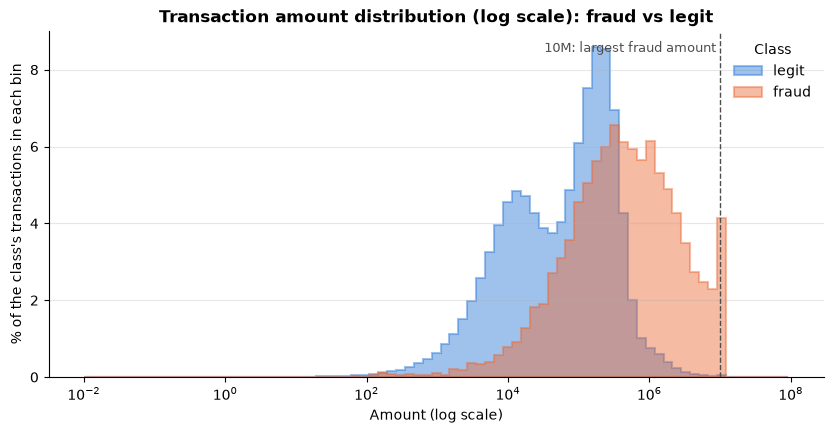

,legit,fraud
count,"6,354,407.0000","8,213.0000"
mean,"178,197.0469","1,467,967.3750"
std,"596,237.0000","2,404,253.0000"
min,0.0100,0.0000
10%,"4,496.3560","37,720.9883"
50%,"74,684.7188","441,423.4375"
90%,"364,373.4313","4,521,723.3000"
max,"92,445,520.0000","10,000,000.0000"


Fraud transactions of exactly 10,000,000: 287
Fraud transactions with amount 0: 16


In [6]:
pos = df[df["amount"] > 0]
bins = np.logspace(np.log10(pos["amount"].min()), np.log10(pos["amount"].max()), 80)

fig, ax = plt.subplots(figsize=(10, 4.5))
for label, flag in [("legit", 0), ("fraud", 1)]:
    amounts = pos.loc[pos["isFraud"] == flag, "amount"]
    ax.hist(amounts, bins=bins, weights=np.full(len(amounts), 100 / len(amounts)),
            histtype="stepfilled", alpha=0.45, color=CLASS_COLORS[label],
            edgecolor=CLASS_COLORS[label], linewidth=1.5, label=label)
ax.set_xscale("log")
ax.axvline(1e7, color="0.3", linestyle="--", linewidth=1)
ax.text(1e7, 0.97, "10M: largest fraud amount ", transform=ax.get_xaxis_transform(),
        ha="right", va="top", fontsize=9, color="0.3")
ax.set_title("Transaction amount distribution (log scale): fraud vs legit")
ax.set_xlabel("Amount (log scale)")
ax.set_ylabel("% of the class's transactions in each bin")
ax.legend(title="Class")
save_fig(fig, "03_amount_distribution")
plt.show()

summary = df.groupby("isFraud")["amount"].describe(percentiles=[0.1, 0.5, 0.9]).T
summary.columns = ["legit", "fraud"]
display(summary)
print("Fraud transactions of exactly 10,000,000:", int(((df["isFraud"] == 1) & (df["amount"] == 1e7)).sum()))
print("Fraud transactions with amount 0:", int(((df["isFraud"] == 1) & (df["amount"] == 0)).sum()))

**Takeaway:** fraudulent transactions are much larger. The **median fraud amount is
about 441k vs about 75k for legit** (roughly 6x). Fraud never exceeds 10,000,000,
and 287 frauds sit at exactly that value, which looks like a per-transaction cap in
the simulator: large frauds are split into 10M chunks. Amount is clearly
informative, but the two distributions overlap heavily, so amount alone will not
separate the classes. 16 frauds have an amount of 0, which is a simulator artefact.

## 5. Fraud over time: per step and per hour of day

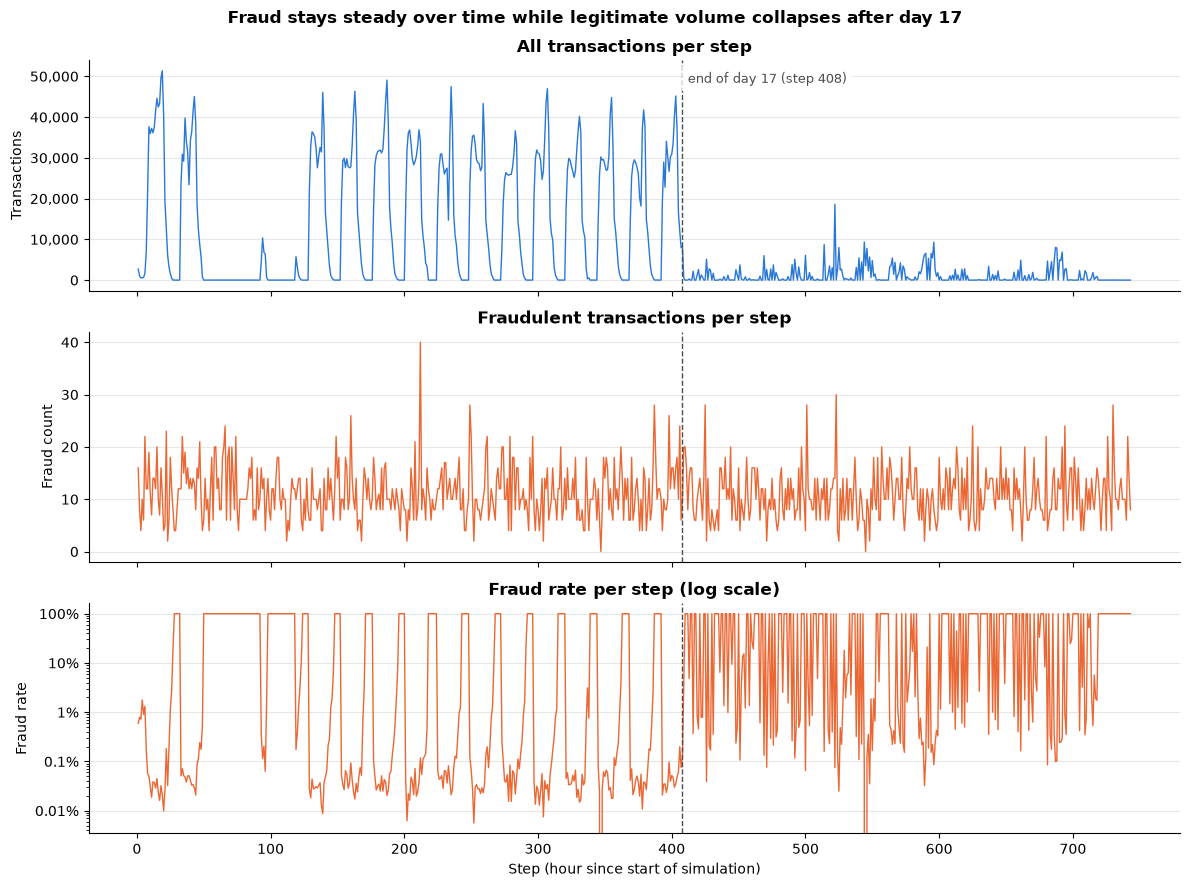

day,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
n_txn,"574,255.0000","455,238.0000","1,070.0000","28,240.0000","9,789.0000","441,005.0000","420,583.0000","449,637.0000","417,919.0000","392,945.0000",...,"53,437.0000","51,012.0000","32,709.0000","57,853.0000","13,885.0000","8,578.0000","14,661.0000","54,890.0000","11,287.0000",272.0000
n_fraud,271.0000,309.0000,310.0000,262.0000,252.0000,228.0000,272.0000,278.0000,255.0000,282.0000,...,256.0000,216.0000,280.0000,240.0000,272.0000,280.0000,248.0000,260.0000,268.0000,272.0000
fraud_rate_pct,0.0472,0.0679,28.9720,0.9278,2.5743,0.0517,0.0647,0.0618,0.0610,0.0718,...,0.4791,0.4234,0.8560,0.4148,1.9589,3.2642,1.6916,0.4737,2.3744,100.0000


In [7]:
by_step = eda.fraud_by_step(df)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(by_step.index, by_step["n_txn"], color=LEGIT_COLOR, linewidth=1)
axes[0].set_title("All transactions per step")
axes[0].set_ylabel("Transactions")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].plot(by_step.index, by_step["n_fraud"], color=FRAUD_COLOR, linewidth=1)
axes[1].set_title("Fraudulent transactions per step")
axes[1].set_ylabel("Fraud count")
axes[2].plot(by_step.index, by_step["fraud_rate_pct"], color=FRAUD_COLOR, linewidth=1)
axes[2].set_yscale("log")
axes[2].set_title("Fraud rate per step (log scale)")
axes[2].set_ylabel("Fraud rate")
axes[2].set_xlabel("Step (hour since start of simulation)")
for ax in axes:
    ax.axvline(408, color="0.3", linestyle="--", linewidth=1)
axes[0].text(412, 0.95, "end of day 17 (step 408)", transform=axes[0].get_xaxis_transform(),
             va="top", fontsize=9, color="0.3",
             bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:g}%"))
axes[2].yaxis.set_minor_formatter(mtick.NullFormatter())
fig.suptitle("Fraud stays steady over time while legitimate volume collapses after day 17",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_fraud_over_time")
plt.show()

by_day = eda.fraud_by_day(df)
display(by_day.T)

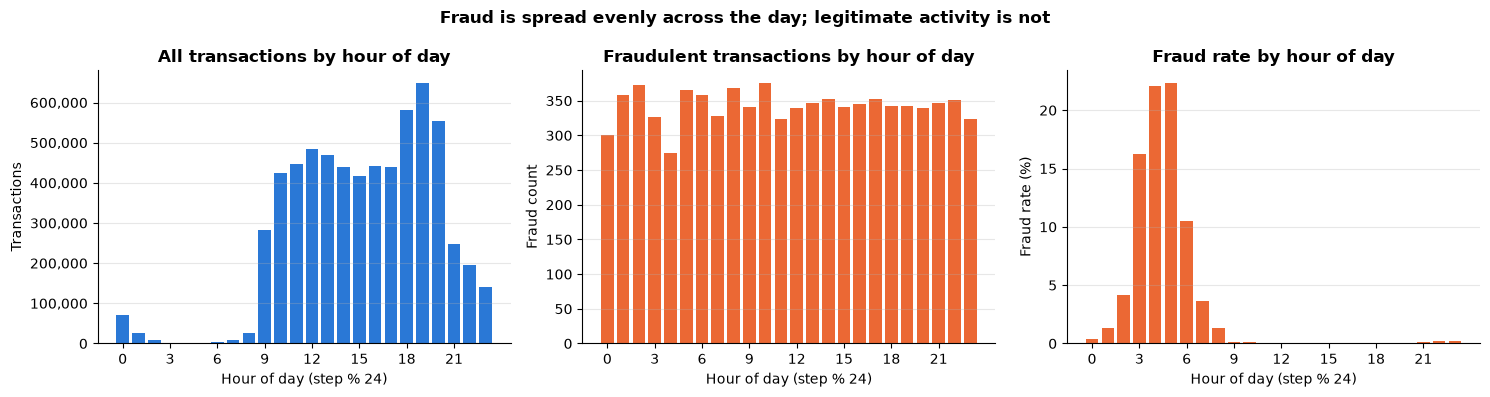

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
n_txn,"71,587.0000","27,111.0000","9,018.0000","2,007.0000","1,241.0000","1,641.0000","3,420.0000","8,988.0000","26,915.0000","283,518.0000",...,"439,653.0000","416,686.0000","441,612.0000","439,941.0000","580,509.0000","647,814.0000","553,728.0000","247,806.0000","194,555.0000","141,257.0000"
n_fraud,300.0000,358.0000,372.0000,326.0000,274.0000,366.0000,358.0000,328.0000,368.0000,341.0000,...,353.0000,341.0000,345.0000,353.0000,343.0000,342.0000,340.0000,347.0000,351.0000,323.0000
fraud_rate_pct,0.4191,1.3205,4.1251,16.2431,22.0790,22.3035,10.4678,3.6493,1.3673,0.1203,...,0.0803,0.0818,0.0781,0.0802,0.0591,0.0528,0.0614,0.1400,0.1804,0.2287


In [8]:
by_hour = eda.fraud_by_hour(df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(by_hour.index, by_hour["n_txn"], color=LEGIT_COLOR)
axes[0].set_title("All transactions by hour of day")
axes[0].set_ylabel("Transactions")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].bar(by_hour.index, by_hour["n_fraud"], color=FRAUD_COLOR)
axes[1].set_title("Fraudulent transactions by hour of day")
axes[1].set_ylabel("Fraud count")
axes[2].bar(by_hour.index, by_hour["fraud_rate_pct"], color=FRAUD_COLOR)
axes[2].set_title("Fraud rate by hour of day")
axes[2].set_ylabel("Fraud rate (%)")
for ax in axes:
    ax.set_xlabel("Hour of day (step % 24)")
    ax.set_xticks(range(0, 24, 3))
fig.suptitle("Fraud is spread evenly across the day; legitimate activity is not",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_fraud_by_hour")
plt.show()

display(by_hour.T)

**Takeaway:** fraud is **spread almost evenly over the timeline**: it appears in 741
of 743 steps, at a median of about 10 frauds per hour and about 260 per day.
Legitimate activity is not even at all:

- **Across days:** volume runs at roughly 350k to 575k transactions a day until
  day 17 (apart from a dip on days 3 to 5), then drops to roughly 10k to 60k a day.
  The steps after 400 hold only **9% of all transactions but 45% of all fraud**. The
  daily fraud rate jumps from about 0.06% to 0.4% to 3%, and on the final day every
  transaction is fraud.
- **Across the hours of a day:** fraud is flat at about 270 to 375 cases per hour,
  while legitimate activity almost stops between roughly 02:00 and 06:00. So the
  fraud rate in those hours is very high (about 22% at hour 4).

**Why this matters for modelling:**
1. A time-based split puts most of the low-volume late period into the test set, so
   the **test fraud rate will be far higher than the training rate**. PR-AUC depends
   on the base rate, so test PR-AUC must always be reported next to the test base
   rate, and it will look better than it would at a realistic 0.13% rate.
2. Hour of day is predictive here only because legitimate volume drops at night, not
   because fraudsters behave differently. It is a simulator artefact that may not
   carry over to real data, so it should be used with care and clearly flagged.

## 6. Balance patterns: emptied origin accounts and empty destinations

Compared within **TRANSFER and CASH_OUT only**, so fraud is measured against
legitimate transactions of the same kind.

class,legit (%),fraud (%)
orig_emptied,90.0951,98.0519
orig_zero_before,47.3732,0.4992
orig_drained,42.7219,97.5527
dest_zero_before,13.9009,65.1528
emptied_and_dest_zero,11.6348,63.2290


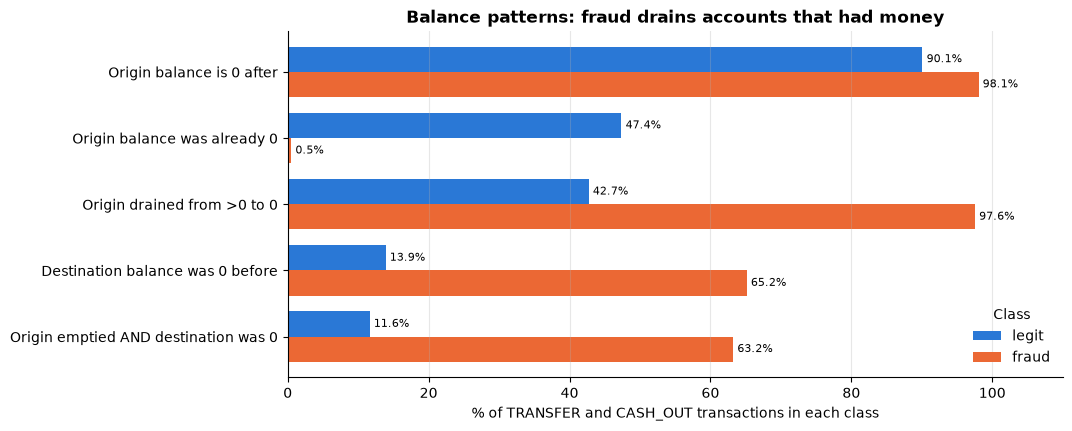

In [9]:
patterns = eda.balance_patterns(df)
display(patterns.T.rename(columns=lambda c: f"{c} (%)"))

labels = {
    "orig_emptied": "Origin balance is 0 after",
    "orig_zero_before": "Origin balance was already 0",
    "orig_drained": "Origin drained from >0 to 0",
    "dest_zero_before": "Destination balance was 0 before",
    "emptied_and_dest_zero": "Origin emptied AND destination was 0",
}
plot_df = patterns.T.rename(index=labels)

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(plot_df))
h = 0.38
ax.barh(y - h / 2, plot_df["legit"], height=h, color=LEGIT_COLOR, label="legit")
ax.barh(y + h / 2, plot_df["fraud"], height=h, color=FRAUD_COLOR, label="fraud")
for i, (l, f) in enumerate(plot_df[["legit", "fraud"]].values):
    ax.annotate(f"{l:.1f}%", (l, i - h / 2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.annotate(f"{f:.1f}%", (f, i + h / 2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("% of TRANSFER and CASH_OUT transactions in each class")
ax.set_title("Balance patterns: fraud drains accounts that had money")
ax.legend(title="Class", loc="lower right")
save_fig(fig, "06_balance_patterns")
plt.show()

**Takeaway:** fraud almost always **drains an account that had money**: about 98% of
frauds take the origin from a positive balance to exactly 0, against roughly 43% of
legitimate transfers and cash-outs. The plain "origin is 0 after" flag looks weaker
(98% vs 90%) only because **47% of legitimate rows already start at a zero origin
balance, against 0.5% of frauds**. That gap is itself a strong signal. Fraud also
goes to a destination with a zero opening balance far more often (65% vs 14%).
Balance-based features look like the most useful inputs. They will be built
carefully, because PaySim balances are known to have inconsistencies.

## 7. Account IDs and the `isFlaggedFraud` column

In [10]:
reuse = eda.account_reuse(df)
display(reuse)
display(eda.id_prefixes(df).to_frame())

,n_rows,n_unique,pct_rows_id_seen_once,max_appearances
nameOrig,"6,362,620.0000","6,353,307.0000",99.7075,3.0000
nameDest,"6,362,620.0000","2,722,362.0000",35.5625,113.0000
nameDest (fraud only),"8,213.0000","8,169.0000",98.9285,2.0000


count
isFraud orig_prefix dest_prefix         
0       C           C            4202912
                    M            2151495
1       C           C               8213

**Takeaway (account IDs):** IDs are almost unique, so they carry no reusable history:

- **`nameOrig`:** 99.7% of rows have an origin ID that never appears again, and no
  origin appears more than 3 times. There is no per-customer history to learn from.
- **`nameDest`:** repeats more (2.7M unique IDs, up to 113 appearances), but the
  **8,213 frauds go to 8,169 distinct destinations, each used at most twice**. So
  there are no repeat "mule" accounts to exploit.

Used as raw features, these IDs would only let a model memorise rows, so they are
excluded, as set out in `CLAUDE.md`. The only structure is the prefix: **merchant (M)
destinations appear only in PAYMENT**, which never contains fraud, and every
TRANSFER and CASH_OUT is customer to customer (C to C). Once the data is restricted
to TRANSFER and CASH_OUT, the prefix adds nothing.

In [11]:
display(eda.flagged_vs_fraud(df))

flagged = df[df["isFlaggedFraud"] == 1]
n_fraud = int(df["isFraud"].sum())
print(f"Flagged transactions: {len(flagged)}, all fraud: {bool(flagged['isFraud'].all())}")
print(f"Flagged types: {flagged['type'].astype(str).unique().tolist()}")
print(f"Smallest flagged amount: {flagged['amount'].min():,.0f}")
print(f"Recall of the legacy flag: {flagged['isFraud'].sum() / n_fraud:.2%} of {n_fraud:,} frauds")

isFraud,fraud,legit,All
isFlaggedFraud,,,
flagged,16,0,16
not flagged,8197,6354407,6362604
All,8213,6354407,6362620


Flagged transactions: 16, all fraud: True
Flagged types: ['TRANSFER']
Smallest flagged amount: 353,874
Recall of the legacy flag: 0.19% of 8,213 frauds


**Takeaway (`isFlaggedFraud`):** this column is the output of the simulator's legacy
business rule (it is documented as flagging very large transfers). It **flagged only
16 transactions, all of them TRANSFER fraud, and missed 8,197 of 8,213 frauds:
precision 100%, recall 0.19%.** It is close to useless as a detector, it is
almost always 0, and it is itself a rule-based prediction derived from the
transaction rather than an independent input. It is **dropped**. At most, it can
serve as a "legacy rule" baseline to beat.

## Key findings

- **Severe class imbalance:** 8,213 frauds in 6.36M transactions (0.129%). Accuracy
  is meaningless here (99.87% by always predicting "legit"), so models are judged
  on PR-AUC, precision and recall.
- **Fraud is confined to TRANSFER and CASH_OUT** (about 50/50 between them). The
  other three types have zero fraud, so modelling only these two types removes 56%
  of rows without losing a single fraud.
- **Fraud drains funded accounts:** about 98% of frauds take the origin from a positive
  balance to exactly 0 (vs about 43% of comparable legit transactions), and 65%
  go to a destination with a zero opening balance (vs 14%). Fraud amounts are
  larger (median about 441k vs 75k) and capped at 10M per transaction.
- **The time axis is non-stationary:** fraud stays at about 260 cases a day, while
  legitimate volume falls by roughly 90% after day 17. The late period holds 9% of
  transactions but 45% of fraud, so a time-based test set will have a much higher
  base rate than training. Test PR-AUC must be read against that base rate.
- **Hour of day is a simulator artefact:** fraud is flat across the day, but legit
  activity almost stops overnight, so the night-time fraud rate is very high. It is
  predictive here, but unlikely to transfer to real data.
- **Excluded columns:** `nameOrig`/`nameDest` are nearly unique and fraud never
  reuses destination accounts, so they offer no history, only memorisation risk.
  `isFlaggedFraud` caught 16 of 8,213 frauds (0.19% recall), so it is dropped and
  kept at most as a legacy-rule baseline.